# Machine Learning Principles

## Import Libraries

In [30]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

## Load Dataset

In [31]:
# Project root
ROOT_DIR = Path.cwd().parent

# Data folder
DATA_DIR = ROOT_DIR / "data"

# Source data files
train_file = DATA_DIR / "fashion-mnist_train.csv"
test_file = DATA_DIR / "fashion-mnist_test.csv"

# Load training and testing datasets
train_df = pd.read_csv(train_file)
test_df = pd.read_csv(test_file)

train_df.head(10)
test_df.head(10)

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,9,8,...,103,87,56,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,...,34,0,0,0,0,0,0,0,0,0
2,2,0,0,0,0,0,0,14,53,99,...,0,0,0,0,63,53,31,0,0,0
3,2,0,0,0,0,0,0,0,0,0,...,137,126,140,0,133,224,222,56,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,2,0,0,0,0,0,44,105,44,10,...,105,64,30,0,0,0,0,0,0,0
6,8,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7,6,0,0,0,0,0,0,0,1,0,...,174,136,155,31,0,1,0,0,0,0
8,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9,0,0,0,0,0,0,0,0,0,0,...,57,70,28,0,2,0,0,0,0,0


## Split Training and Test Data

In [32]:
# Separate features and labels
X_train = train_df.drop("label", axis=1).values
y_train = train_df["label"].values

X_test = test_df.drop("label", axis=1).values
y_test = test_df["label"].values

print("Training data shape:", X_train.shape)
print("Training labels shape:", y_train.shape)

print("Testing data shape:", X_test.shape)
print("Testing labels shape:", y_test.shape)

Training data shape: (60000, 784)
Training labels shape: (60000,)
Testing data shape: (10000, 784)
Testing labels shape: (10000,)


### Normalize Pixel Values

In [33]:
# Normalize pixel values to scale them between 0 and 1
X_train = X_train.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0

print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Minimum pixel value: 0.0
Maximum pixel value: 1.0
Training shape: (60000, 784)
Testing shape: (10000, 784)


## K-NN Algorithm Implementation

### Euclidean Distance

In [34]:
def euclidean_distance(x1, x2, axis=None):
    return np.sqrt(np.sum((x1 - x2) ** 2, axis=axis))

In [35]:
image1 = np.array([1, 2, 3])
image2 = np.array([4, 5, 6])

distance = euclidean_distance(image1, image2)

print("Euclidean distance:", distance)

Euclidean distance: 5.196152422706632


### Find the K Nearest Neighbors

In [36]:
def get_neighbors(X_train, X_batch, k=5, X_train_squared=None):

    if X_train_squared is None:
        X_train_squared = np.sum(X_train ** 2, axis=1)

    # Calculate the squared Euclidean distances between the batch and training data
    distances = (
        np.sum(X_batch ** 2, axis=1, keepdims=True)
        + X_train_squared[None, :]
        - 2 * (X_batch @ X_train.T)
    )

    np.maximum(distances, 0, out=distances)

    return np.argpartition(distances, k - 1, axis=1)[:, :k]

### Majority Voting

In [37]:
def majority_vote(neighbors, y_train):
    # Retrieve the labels of the nearest neighbors
    neighbor_labels = y_train[neighbors]

    # Count occurrences of each class
    votes = np.bincount(neighbor_labels, minlength=10)

    # Return the class with the most votes
    prediction = np.argmax(votes)

    return prediction

### Make Predictions

In [38]:
def knn_predict(X_train, y_train, X_test, k=5, batch_size=64):

    predictions = []

    # Precompute squared training image values once
    X_train_squared = np.sum(X_train ** 2, axis=1)

    # Process test images in batches
    for start in range(0, len(X_test), batch_size):

        X_batch = X_test[start:start + batch_size]

        # Find the k nearest neighbors for every image in the batch
        neighbors = get_neighbors(X_train, X_batch, k, X_train_squared)

        # Majority vote for each test image
        for neighbor_indices in neighbors:
            predictions.append(majority_vote(neighbor_indices, y_train))

    return np.array(predictions)

In [39]:
y_pred_knn = knn_predict(
    X_train,
    y_train,
    X_test,
    k=5
)

### Evaluate KNN Accuracy

In [40]:
knn_accuracy = accuracy_score(y_test, y_pred_knn)

print(f"KNN Accuracy: {knn_accuracy:.4f}")
print(f"KNN Accuracy: {knn_accuracy * 100:.2f}%")

KNN Accuracy: 0.8589
KNN Accuracy: 85.89%


## Random Forest Algorithm

### Initialize Random Forest

In [41]:
# Initialize Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

### Train the Model

In [42]:
start_time = time.time()

rf_model.fit(X_train, y_train)

end_time = time.time()

rf_training_time = end_time - start_time
print(f"Random Forest Training Time: {rf_training_time:.2f} seconds")

Random Forest Training Time: 15.75 seconds


### Create Predictions

In [43]:
start_time = time.time()

y_pred_rf = rf_model.predict(X_test)

end_time = time.time()

rf_prediction_time = end_time - start_time

print("Random Forest Predictions:", y_pred_rf[:10])
print("Actual Labels:           ", y_test[:10])

print(f"\nRandom Forest Prediction Time: {rf_prediction_time:.2f} seconds")

Random Forest Predictions: [0 1 2 2 3 6 8 6 5 0]
Actual Labels:            [0 1 2 2 3 2 8 6 5 0]

Random Forest Prediction Time: 0.11 seconds


### Evaluate Accuracy

In [44]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print(f"Random Forest Accuracy: {rf_accuracy:.4f}")
print(f"Random Forest Accuracy: {rf_accuracy * 100:.2f}%")

Random Forest Accuracy: 0.8846
Random Forest Accuracy: 88.46%


## Evaluate and Compare Both Models

In [45]:
from sklearn.metrics import classification_report

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

In [46]:
print("========== KNN CLASSIFICATION REPORT ==========")
print(classification_report(
    y_test,
    y_pred_knn,
    target_names=class_names,
    zero_division=0
))

print(f"KNN Accuracy: {knn_accuracy:.4f}")
print(f"KNN Accuracy: {knn_accuracy * 100:.2f}%")


========== KNN CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

 T-shirt/top       0.77      0.87      0.82      1000
     Trouser       0.99      0.96      0.98      1000
    Pullover       0.75      0.81      0.78      1000
       Dress       0.91      0.88      0.90      1000
        Coat       0.79      0.80      0.79      1000
      Sandal       1.00      0.82      0.90      1000
       Shirt       0.68      0.58      0.63      1000
     Sneaker       0.87      0.94      0.91      1000
         Bag       0.98      0.95      0.97      1000
  Ankle boot       0.88      0.96      0.92      1000

    accuracy                           0.86     10000
   macro avg       0.86      0.86      0.86     10000
weighted avg       0.86      0.86      0.86     10000

KNN Accuracy: 0.8589
KNN Accuracy: 85.89%


In [47]:
print("========== RANDOM FOREST CLASSIFICATION REPORT ==========")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=class_names,
    zero_division=0
))

print(f"Random Forest Accuracy: {rf_accuracy:.4f}")
print(f"Random Forest Accuracy: {rf_accuracy * 100:.2f}%")

========== RANDOM FOREST CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

 T-shirt/top       0.82      0.86      0.84      1000
     Trouser       0.99      0.97      0.98      1000
    Pullover       0.80      0.80      0.80      1000
       Dress       0.89      0.94      0.91      1000
        Coat       0.80      0.86      0.83      1000
      Sandal       0.98      0.95      0.96      1000
       Shirt       0.75      0.61      0.67      1000
     Sneaker       0.92      0.94      0.93      1000
         Bag       0.95      0.97      0.96      1000
  Ankle boot       0.94      0.95      0.94      1000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000

Random Forest Accuracy: 0.8846
Random Forest Accuracy: 88.46%


### Model Performance Comparison

In [49]:
knn_metrics = {
    "Precision": precision_score(y_test, y_pred_knn, average="macro"),
    "Recall": recall_score(y_test, y_pred_knn, average="macro"),
    "F1-Score": f1_score(y_test, y_pred_knn, average="macro"),
    "Accuracy": accuracy_score(y_test, y_pred_knn)
}

rf_metrics = {
    "Precision": precision_score(y_test, y_pred_rf, average="macro"),
    "Recall": recall_score(y_test, y_pred_rf, average="macro"),
    "F1-Score": f1_score(y_test, y_pred_rf, average="macro"),
    "Accuracy": accuracy_score(y_test, y_pred_rf)
}

comparison_df = pd.DataFrame({
    "KNN": knn_metrics,
    "Random Forest": rf_metrics
})

print("MODEL PERFORMANCE COMPARISON")
display(comparison_df.round(4))

MODEL PERFORMANCE COMPARISON


,KNN,Random Forest
Precision,0.8614,0.8832
Recall,0.8589,0.8846
F1-Score,0.8580,0.8829
Accuracy,0.8589,0.8846


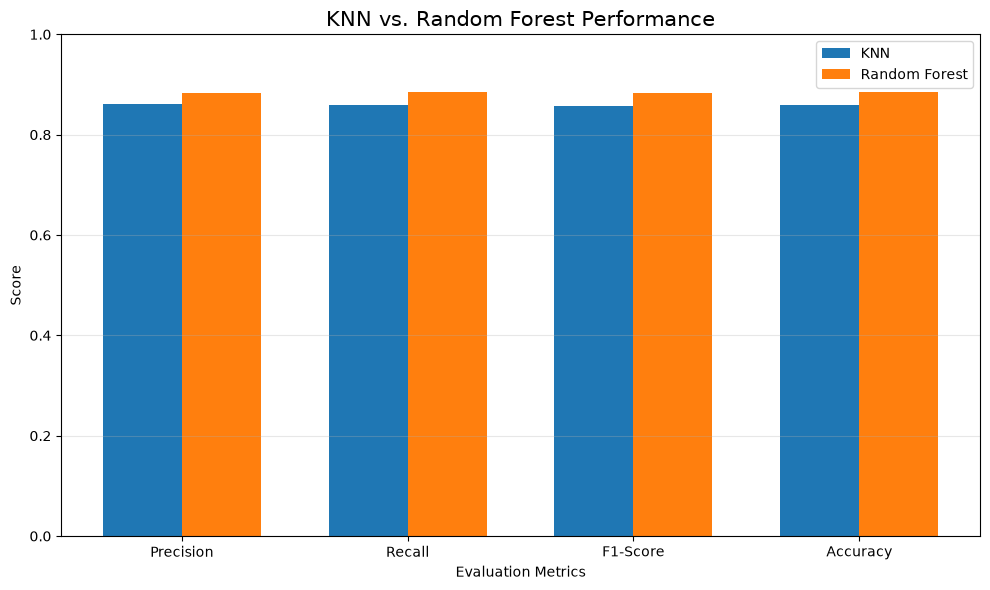

In [50]:

from sklearn import metrics


knn_scores = [0.8614, 0.8589, 0.8580, 0.8589]
rf_scores = [0.8832, 0.8846, 0.8829, 0.8846]

# Bar positions
x = np.arange(len(knn_metrics))
width = 0.35

# Create grouped bar chart
plt.figure(figsize=(10, 6))

plt.bar(x - width/2, knn_scores, width, label="KNN")
plt.bar(x + width/2, rf_scores, width, label="Random Forest")

# Labels and formatting
plt.title("KNN vs. Random Forest Performance", fontsize=15)
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.xticks(x, knn_metrics)
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()